# Retail Customer Sales Analysis — Complete Project Notebook
**GitHub Repository:** `[https://github.com/username/retail-customer-sales-analysis]`

This Jupyter Notebook (`.ipynb`) contains all code, markdown explanations, data quality cleaning steps, feature engineering, exploratory analysis, visualizations, RFM segmentation, and return prediction modeling for `retail_customer_sales_dataset.csv` (2023–2024).


## 1. Setup & Initial Data Inspection
Load required libraries and inspect dataset dimensions, data types, missing values, and sample records.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('retail_customer_sales_dataset.csv')
print('Shape:', df.shape)
print('Missing values:\n', df.isnull().sum()[df.isnull().sum() > 0])


Shape: (7084, 24)
Missing values:
Delivery_Date         106
Age                   142
Income                253
Discount               71
Customer_Rating       428
Satisfaction_Level    179
dtype: int64


## 2. Data Quality Audit & Cleaning
We resolve data quality anomalies before analysis:
- **Dates & Duplicates:** Parse mixed date formats (`YYYY-MM-DD` and `DD/MM/YYYY`) and deduplicate by `Transaction_ID` (removing 84 duplicate rows to keep 7,000 unique orders).
- **Categorical Standardization:** Standardize `Gender` and `Region` casing and typos (`Nort`, `Sth`, `WEST`, `M`, `F`).
- **Outliers & Missing Values:** Fix impossible ages (`< 18` or `> 100`), recover invalid/missing `Discount` values from `Sales / (Unit_Price * Quantity)`, remove negative delivery lead times, and impute remaining nulls.


In [2]:
cleaned = df.copy()
cleaned['Order_Date'] = pd.to_datetime(cleaned['Order_Date'], format='mixed', dayfirst=True, errors='coerce')
cleaned['Delivery_Date'] = pd.to_datetime(cleaned['Delivery_Date'], format='mixed', dayfirst=True, errors='coerce')
cleaned = cleaned.drop_duplicates(subset=['Transaction_ID'], keep='first').reset_index(drop=True)

gender_map = {'male': 'Male', 'm': 'Male', 'female': 'Female', 'f': 'Female'}
cleaned['Gender'] = cleaned['Gender'].astype(str).str.strip().str.lower().map(gender_map).fillna('Unknown')

region_map = {'north': 'North', 'nort': 'North', 'south': 'South', 'sth': 'South', 'east': 'East', 'west': 'West'}
cleaned['Region'] = cleaned['Region'].astype(str).str.strip().str.lower().map(region_map).fillna('Unknown')

cleaned.loc[(cleaned['Age'] < 18) | (cleaned['Age'] > 100), 'Age'] = np.nan
cleaned['Age'] = cleaned['Age'].fillna(cleaned['Age'].median())

invalid_disc = (~cleaned['Discount'].between(0, 1)) | (cleaned['Discount'].isna())
implied_disc = 1.0 - (cleaned['Sales'] / (cleaned['Unit_Price'] * cleaned['Quantity']))
cleaned.loc[invalid_disc, 'Discount'] = implied_disc.loc[invalid_disc].clip(0.0, 1.0).round(2)

cleaned['Income'] = cleaned['Income'].fillna(cleaned.groupby('Customer_Segment')['Income'].transform('median'))
cleaned['Customer_Rating'] = cleaned['Customer_Rating'].fillna(cleaned['Customer_Rating'].median())
cleaned['Satisfaction_Level'] = cleaned['Satisfaction_Level'].fillna(cleaned['Satisfaction_Level'].mode()[0])

invalid_delivery = cleaned['Delivery_Date'] < cleaned['Order_Date']
cleaned.loc[invalid_delivery, 'Delivery_Date'] = pd.NaT
cleaned['Delivery_Days'] = (cleaned['Delivery_Date'] - cleaned['Order_Date']).dt.days
cleaned['Delivery_Days'] = cleaned['Delivery_Days'].fillna(cleaned.groupby('Delivery_Mode')['Delivery_Days'].transform('median'))
cleaned['Profit_Margin_Pct'] = np.where(cleaned['Sales'] > 0, (cleaned['Profit'] / cleaned['Sales']) * 100, 0.0)
cleaned['Order_Year'] = cleaned['Order_Date'].dt.year
cleaned['Order_Month'] = cleaned['Order_Date'].dt.to_period('M').astype(str)
cleaned['Returned_Flag'] = (cleaned['Returned'].str.strip().str.lower() == 'yes').astype(int)

print(f'Cleaned rows: {len(cleaned):,} | Total Sales: {cleaned["Sales"].sum():,.2f} | Total Profit: {cleaned["Profit"].sum():,.2f}')


Cleaned rows: 7,000 | Total Sales: 76,731,189.27 | Total Profit: 25,127,882.66


## 3. Exploratory Data Analysis & Visualizations
Compare revenue, profit margins, and return rates across product categories, regions, and customer satisfaction levels.


                  Orders      Revenue       Profit  Avg_Margin_Pct  Return_Rate_Pct
Product_Category                                                                   
Electronics         1975  37639557.39  12352219.50           32.87            12.10
Furniture            979  26057893.88   8547604.77           32.92            13.18
Clothing            1533   7781680.39   2521027.84           32.28            13.50
Grocery             1669   2685875.10    874840.19           32.42            12.46
Office Supplies      844   2566182.51    832190.36           32.78            11.49

        Orders      Revenue      Profit  Return_Rate_Pct
Region                                                  
East      1765  20018192.35  6607664.00            11.95
West      1798  19758995.56  6472920.07            12.79
South     1761  18890109.55  6177763.05            12.27
North     1676  18063891.81  5869535.54            13.31


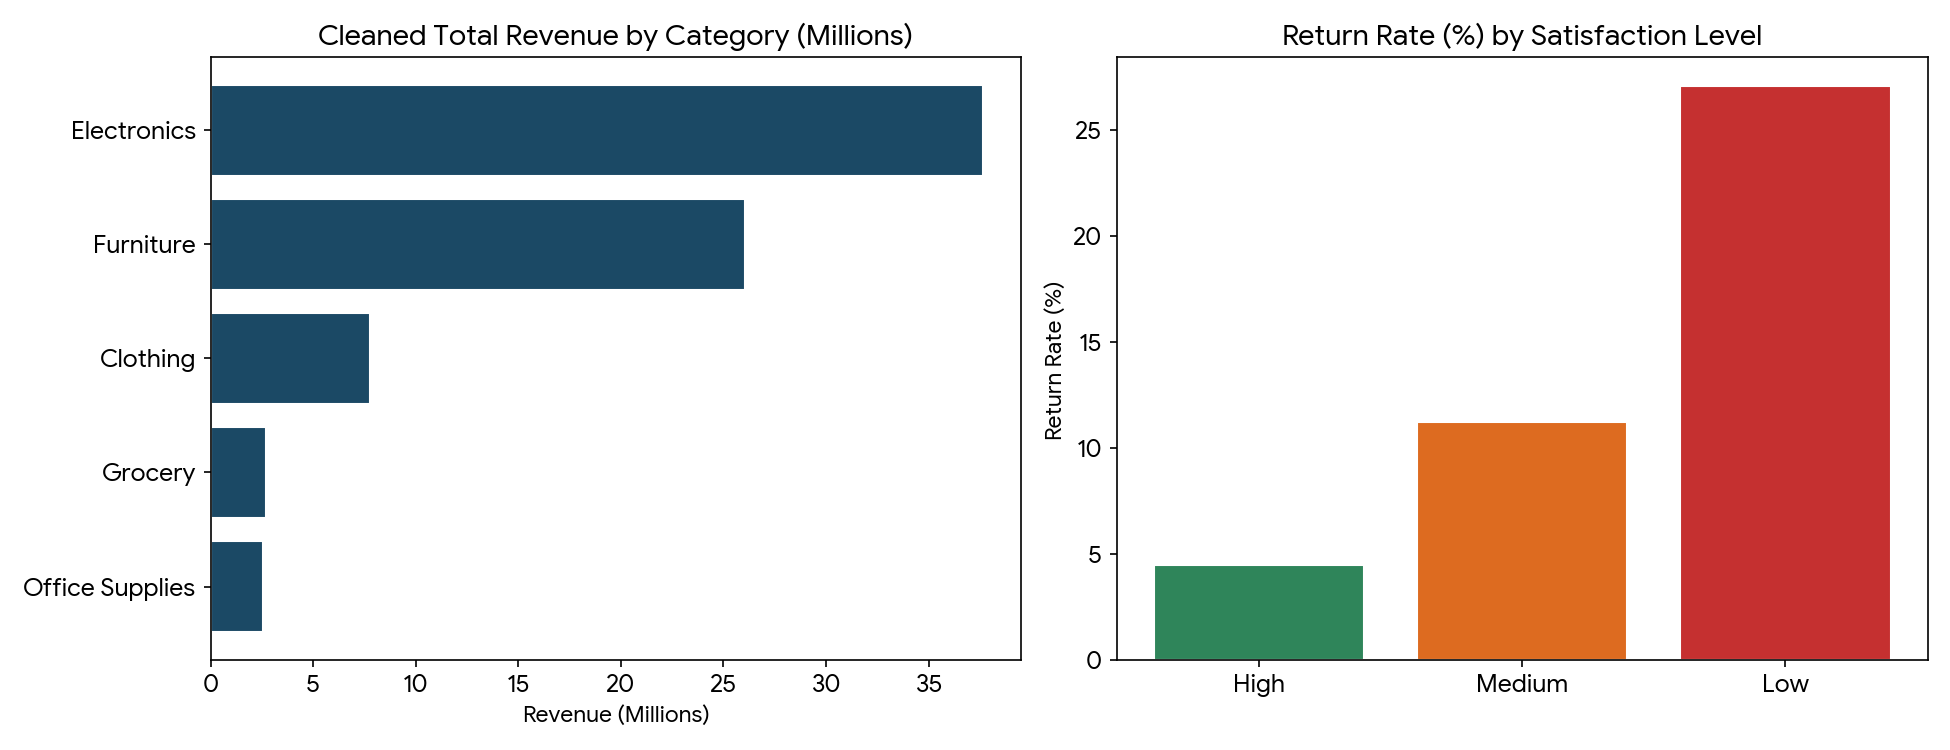

In [3]:
cat_summary = cleaned.groupby('Product_Category').agg(
    Orders=('Transaction_ID', 'count'),
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Margin_Pct=('Profit_Margin_Pct', 'mean'),
    Return_Rate_Pct=('Returned_Flag', lambda x: x.mean() * 100)
).sort_values('Revenue', ascending=False).round(2)
print(cat_summary)

reg_summary = cleaned.groupby('Region').agg(
    Orders=('Transaction_ID', 'count'),
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Return_Rate_Pct=('Returned_Flag', lambda x: x.mean() * 100)
).sort_values('Revenue', ascending=False).round(2)
print('\n', reg_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cat_grp = cleaned.groupby('Product_Category')['Sales'].sum().sort_values(ascending=True)
axes[0].barh(cat_grp.index, cat_grp.values / 1e6, color='#1b4965')
axes[0].set_title('Cleaned Total Revenue by Category (Millions)', fontweight='bold')
sat_grp = cleaned.groupby('Satisfaction_Level')['Returned_Flag'].mean().reindex(['High', 'Medium', 'Low']) * 100
axes[1].bar(sat_grp.index, sat_grp.values, color=['#2f855a', '#dd6b20', '#c53030'])
axes[1].set_title('Return Rate (%) by Satisfaction Level', fontweight='bold')
plt.tight_layout()
plt.show()


## 4. RFM Customer Segmentation & Return Risk Classification
Score customers on Recency, Frequency, and Monetary value, and train a Random Forest classifier to predict order returns.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

snapshot_date = cleaned['Order_Date'].max() + pd.Timedelta(days=1)
rfm = cleaned.groupby('Customer_ID').agg(
    Recency_Days=('Order_Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Transaction_ID', 'count'),
    Monetary=('Sales', 'sum')
).reset_index()
rfm['R_Score'] = pd.qcut(rfm['Recency_Days'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels=[1, 2, 3, 4]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']
rfm['Segment_Tier'] = pd.cut(rfm['RFM_Score'], bins=[2, 5, 8, 10, 12], labels=['At-Risk / Low', 'Regular', 'Loyal', 'Champions'])
print('RFM Segment Tiers:\n', rfm['Segment_Tier'].value_counts())

features = ['Age', 'Gender', 'Income', 'Region', 'Customer_Segment', 'Product_Category',
            'Quantity', 'Unit_Price', 'Discount', 'Payment_Method', 'Delivery_Mode',
            'Customer_Rating', 'Satisfaction_Level', 'Delivery_Days']
X, y = cleaned[features], cleaned['Returned_Flag']
num_cols = ['Age', 'Income', 'Quantity', 'Unit_Price', 'Discount', 'Customer_Rating', 'Delivery_Days']
cat_cols = ['Gender', 'Region', 'Customer_Segment', 'Product_Category', 'Payment_Method', 'Delivery_Mode', 'Satisfaction_Level']
prep = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])
clf = Pipeline([('prep', prep), ('model', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'))])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
clf.fit(X_train, y_train)
print(f'\nROC-AUC: {roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]):.4f}')
print(classification_report(y_test, clf.predict(X_test), digits=3))


RFM Segment Tiers:
Segment_Tier
Regular          585
Loyal            392
At-Risk / Low    387
Champions        212

ROC-AUC: 0.7994
              precision    recall  f1-score   support

           0      0.875     0.993     0.930      1224
           1      0.182     0.011     0.021       176

    accuracy                          0.869      1400
   macro avg      0.528     0.502     0.476      1400
weighted avg      0.788     0.869     0.816      1400
